In [2]:
from pathlib import Path

DATA_DIR = Path("data/raw")

class_names = [
    "Crazing",
    "Inclusion",
    "Patches",
    "Pitted_Surface",
    "Rolled-in_Scale",
    "Scratches"
]

for class_name in class_names:

    folder = DATA_DIR / class_name

    if folder.exists():
        images = list(folder.glob("*"))

        print(class_name, ":", len(images), "files")

    else:
        print("Missing folder:", folder)

Missing folder: data\raw\Crazing
Missing folder: data\raw\Inclusion
Missing folder: data\raw\Patches
Missing folder: data\raw\Pitted_Surface
Missing folder: data\raw\Rolled-in_Scale
Missing folder: data\raw\Scratches


In [3]:
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root="data/raw",
    transform=transform
)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data/raw'

In [4]:
import matplotlib.pyplot as plt

image, label = dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class:", dataset.classes[label])

plt.imshow(image.permute(1, 2, 0))
plt.title(dataset.classes[label])
plt.axis("off")
plt.show()

NameError: name 'dataset' is not defined

In [5]:
from torch.utils.data import random_split

total = len(dataset)

train_size = int(0.70 * total)
val_size = int(0.15 * total)
test_size = total - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=__import__("torch").Generator().manual_seed(42)
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

NameError: name 'dataset' is not defined

In [6]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Batch images:", images.shape)
print("Batch labels:", labels.shape)

NameError: name 'train_dataset' is not defined

In [7]:
https://www.kaggle.com/datasets/kaustubhdikshit/neu-surface-defect-database

SyntaxError: invalid syntax (3818579024.py, line 1)

In [8]:
from pathlib import Path

DATA_DIR = Path("data/raw")

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        print(folder.name, len(list(folder.glob("*"))))

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data\\raw'

In [9]:
from pathlib import Path

# Automatically find the project root or point explicitly to ../data/raw
DATA_DIR = Path("../data/raw")

if not DATA_DIR.exists():
    # Fallback if you opened the notebook from the root directory instead
    DATA_DIR = Path("data/raw")

print("Resolved path:", DATA_DIR.resolve())

if DATA_DIR.exists():
    for item in sorted(DATA_DIR.iterdir()):
        print(item.name, "—", "Directory" if item.is_dir() else f"File ({item.stat().st_size / 1024:.1f} KB)")
else:
    print("Directory still not found. Check your folder structure.")

Resolved path: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw
crazing — Directory
inclusion — Directory
patches — Directory
pitted_surface — Directory
rolled-in_scale — Directory
scratches — Directory


In [11]:
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

# Point one level up to reach the project root's data folder
dataset = datasets.ImageFolder(
    root="../data/raw",
    transform=transform
)

print("Classes found:", dataset.classes)
print("Total images:", len(dataset))

Classes found: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Total images: 1440


Image shape: torch.Size([3, 64, 64])
Label: 0
Class: crazing


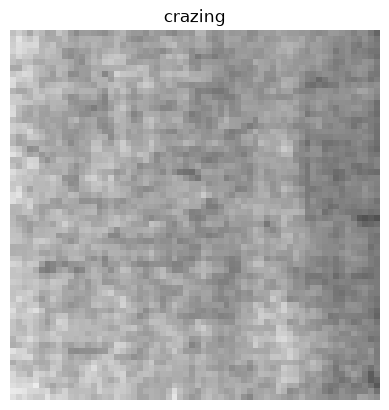

In [12]:
import matplotlib.pyplot as plt

image, label = dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class:", dataset.classes[label])

plt.imshow(image.permute(1, 2, 0))
plt.title(dataset.classes[label])
plt.axis("off")
plt.show()

In [13]:
from torch.utils.data import random_split

total = len(dataset)

train_size = int(0.70 * total)
val_size = int(0.15 * total)
test_size = total - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=__import__("torch").Generator().manual_seed(42)
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 1007
Validation: 216
Testing: 217


In [14]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Batch images:", images.shape)
print("Batch labels:", labels.shape)

Batch images: torch.Size([16, 3, 64, 64])
Batch labels: torch.Size([16])


In [16]:
from pathlib import Path

# Explicitly point to your deep learning project's data folder
# Replace this with your actual absolute path if needed, or check ../data/raw
DATA_DIR = Path("../data/raw") 

if not DATA_DIR.exists():
    # Try looking in the current directory directly
    DATA_DIR = Path("data/raw")

if not DATA_DIR.exists():
    # Try one level up and into project root if you are nested deep
    DATA_DIR = Path("C:/Users/amith/Desktop/Confidential/Misc Projects/P10/ai_engineering_portfolio/project_02_deep_learning/data/raw")

print("Resolved path:", DATA_DIR.resolve())

if DATA_DIR.exists():
    for folder in sorted(DATA_DIR.iterdir()):
        if folder.is_dir():
            print(folder.name, len(list(folder.glob("*"))))
else:
    print("Directory not found. Please verify where your data/raw folder is located.")

Resolved path: C:\Users\amith\Desktop\Confidential\Misc Projects\P10\ai_engineering_portfolio\project_02_deep_learning\data\raw
crazing 240
inclusion 240
patches 240
pitted_surface 240
rolled-in_scale 240
scratches 240
